# PREPARING DATA

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

In [2]:
list(Path("datasets").rglob("*.csv"))

[]

In [3]:
df_employees = pd.read_csv("../datasets/Employee.csv")
df_reviews = pd.read_csv("../datasets/PerformanceRating.csv")

In [4]:
print("Employees:", df_employees.shape)

Employees: (1470, 23)


In [5]:
print("Employees columns:")
print(df_employees.columns.tolist())

Employees columns:
['EmployeeID', 'FirstName', 'LastName', 'Gender', 'Age', 'BusinessTravel', 'Department', 'DistanceFromHome (KM)', 'State', 'Ethnicity', 'Education', 'EducationField', 'JobRole', 'MaritalStatus', 'Salary', 'StockOptionLevel', 'OverTime', 'HireDate', 'Attrition', 'YearsAtCompany', 'YearsInMostRecentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [6]:
print("Reviews:", df_reviews.shape)

Reviews: (6709, 11)


In [7]:
print("\nReviews columns:")
print(df_reviews.columns.tolist())


Reviews columns:
['PerformanceID', 'EmployeeID', 'ReviewDate', 'EnvironmentSatisfaction', 'JobSatisfaction', 'RelationshipSatisfaction', 'TrainingOpportunitiesWithinYear', 'TrainingOpportunitiesTaken', 'WorkLifeBalance', 'SelfRating', 'ManagerRating']


In [8]:
df_employees.head()

,EmployeeID,FirstName,LastName,Gender,Age,BusinessTravel,Department,DistanceFromHome (KM),State,Ethnicity,Education,EducationField,JobRole,MaritalStatus,Salary,StockOptionLevel,OverTime,HireDate,Attrition,YearsAtCompany,YearsInMostRecentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,3012-1A41,Leonelle,Simco,Female,30,Some Travel,Sales,27,IL,White,5,Marketing,Sales Executive,Divorced,102059,1,No,2012-01-03,No,10,4,9,7
1,CBCB-9C9D,Leonerd,Aland,Male,38,Some Travel,Sales,23,CA,White,4,Marketing,Sales Executive,Single,157718,0,Yes,2012-01-04,No,10,6,10,0
2,95D7-1CE9,Ahmed,Sykes,Male,43,Some Travel,Human Resources,29,CA,Asian or Asian American,4,Marketing,HR Business Partner,Married,309964,1,No,2012-01-04,No,10,6,10,8
3,47A0-559B,Ermentrude,Berrie,Non-Binary,39,Some Travel,Technology,12,IL,White,3,Computer Science,Engineering Manager,Married,293132,0,No,2012-01-05,No,10,10,10,0
4,42CC-040A,Stace,Savege,Female,29,Some Travel,Human Resources,29,CA,White,2,Technical Degree,Recruiter,Single,49606,0,No,2012-01-05,Yes,6,1,1,6


In [9]:
df_workforce = df_employees.copy()

In [10]:
# Binary target variable for logistic regression
df_workforce["AttritionBinary"] = (df_workforce["Attrition"].map({"No": 0, "Yes": 1}))

In [11]:
print("Employees:", len(df_workforce))
print("Unique employees:", df_workforce["EmployeeID"].nunique())
print("Leavers:", df_workforce["AttritionBinary"].sum())
print("Missing target values:", df_workforce["AttritionBinary"].isna().sum())

Employees: 1470
Unique employees: 1470
Leavers: 237
Missing target values: 0


In [12]:
# Adding the hire date to the ratings table
df_reviews_merged = df_reviews.merge(
    df_workforce[["EmployeeID", "HireDate"]],
    on="EmployeeID",
    how="left",
    validate="many_to_one"
)

In [13]:
# Converting dates and filtering records
df_reviews_merged["ReviewDate"] = pd.to_datetime(df_reviews_merged["ReviewDate"])
df_reviews_merged["HireDate"] = pd.to_datetime(df_reviews_merged["HireDate"])
df_eligible_reviews = df_reviews_merged[df_reviews_merged["ReviewDate"] >= df_reviews_merged["HireDate"]].copy()

In [14]:
# Selecting the most recent rating
df_latest_reviews = (
    df_eligible_reviews
    .sort_values("ReviewDate")
    .drop_duplicates(subset="EmployeeID", keep="last")
    .copy()
)

In [15]:
# checking
assert len(df_latest_reviews) == 1217
assert df_latest_reviews["EmployeeID"].is_unique

In [16]:
# Preparing the reviewed cohort
df_reviewed = df_workforce.merge(
    df_latest_reviews.drop(columns="HireDate"),
    on="EmployeeID",
    how="inner",
    validate="one_to_one"
)

In [17]:
# Saving processed datasets
processed_dir = Path("datasets/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

df_workforce.to_csv(processed_dir / "workforce_analysis.csv", index=False)
df_reviewed.to_csv(processed_dir / "reviewed_analysis.csv", index=False)

# LOAD PREPARED DATA

In [18]:
# Reloading processed datasets
df_workforce = pd.read_csv("../datasets/processed/workforce_analysis.csv",parse_dates=["HireDate"])

df_reviewed = pd.read_csv("../datasets/processed/reviewed_analysis.csv",parse_dates=["HireDate", "ReviewDate"])

# ANALYSIS

## OverTime vs Attrition: Chi-Square Test

In [19]:
from scipy.stats import chi2_contingency

In [20]:
# Overtime vs Attrition
table = pd.crosstab(df_workforce["OverTime"], df_workforce["Attrition"])
table

Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


In [21]:
# Pearson's Chi-square test
chi2, p, dof, expected = chi2_contingency(table, correction=False)

print(f"Chi-square: {chi2:.2f}")
print(f"p-value: {p:.10f}")
print(f"Degrees of freedom: {dof}")
print(f"Minimum expected count: {expected.min():.2f}")

Chi-square: 89.04
p-value: 0.0000000000
Degrees of freedom: 1
Minimum expected count: 67.07


In [22]:
# Cramer's V
n = table.to_numpy().sum()
cramers_v_ot = np.sqrt(chi2 / (n * (min(table.shape) - 1)))

print("Cramér's V:", round(cramers_v_ot, 3))

Cramér's V: 0.246


> Statistically significant

In [23]:
# Odds Ratio (OR) i 95% Confidence Interval

from statsmodels.stats.contingency_tables import Table2x2
result = Table2x2(table.loc[["Yes", "No"], ["Yes", "No"]].to_numpy())
ci_low, ci_high = result.oddsratio_confint()

print("Odds Ratio:", round(result.oddsratio, 2))
print("95% CI:", round(ci_low, 2), "-", round(ci_high, 2))

Odds Ratio: 3.77
95% CI: 2.83 - 5.03


> Approximately 3.77 times higher odds of recorded employee attrition among employees working overtime compared to those not working overtime.

In [24]:
# Difference in recorded attrition shares

share_ot = table.loc["Yes", "Yes"] / table.loc["Yes"].sum()
share_no_ot = table.loc["No", "Yes"] / table.loc["No"].sum()
risk_diff = (share_ot - share_no_ot) * 100

print("Risk Difference:", round(risk_diff, 2), "pp")

Risk Difference: 20.09 pp


> A 20.09 pp higher recorded attrition rate among employees working overtime compared to those not working overtime.

In [25]:
# 95% CI for the difference in attrition shares

from statsmodels.stats.proportion import confint_proportions_2indep

ci_low, ci_high = confint_proportions_2indep(
    table.loc["Yes", "Yes"],
    table.loc["Yes"].sum(),
    table.loc["No", "Yes"],
    table.loc["No"].sum(),
    method="newcomb"
)

print("95% CI:", round(ci_low * 100, 2), "-", round(ci_high * 100, 2), "pp")


95% CI: 15.42 - 24.99 pp


In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

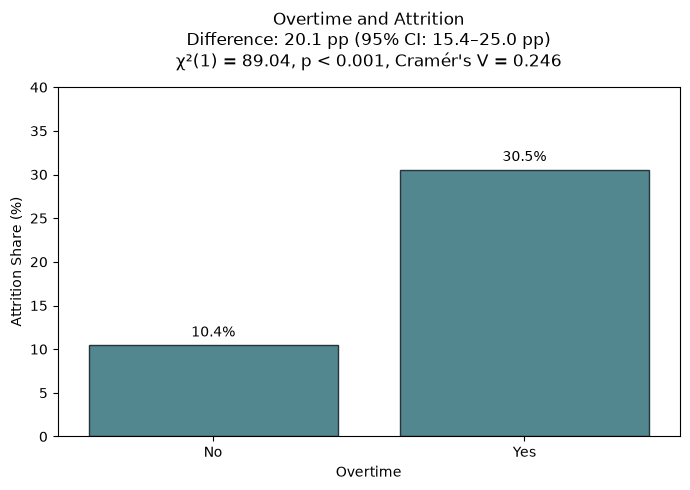

In [27]:
# Attrition share by overtime status
plot_data = pd.DataFrame({
    "Overtime": ["No", "Yes"],
    "Attrition Share (%)": [share_no_ot * 100, share_ot * 100]
})

fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(
    data=plot_data,
    x="Overtime",
    y="Attrition Share (%)",
    color="#488E99",
    edgecolor="#26343C",
    linewidth=1.0,
    errorbar=None,
    ax=ax
)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4)

p_text = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

ax.set_title(
    f"Overtime and Attrition\n"
    f"Difference: {risk_diff:.1f} pp "
    f"(95% CI: {ci_low*100:.1f}–{ci_high*100:.1f} pp)\n"
    f"χ²({dof}) = {chi2:.2f}, {p_text}, Cramér's V = {cramers_v_ot:.3f}",
    pad=15
)

ax.set_xlabel("Overtime")
ax.set_ylabel("Attrition Share (%)")
ax.set_ylim(0, 40)

plt.tight_layout()
plt.show()

## Salary vs Attrition: Chi-Square Test

In [28]:
# Creating salary bands
df_workforce["SalaryBand"] = pd.cut(
    df_workforce["Salary"],
    bins=[-np.inf, 45000, 75000, 150000, np.inf],
    labels=["Below 45k", "45k-75k", "75k-150k", "150k+"],
    right=False
)

In [29]:
# crosstable
table_salary = pd.crosstab(
    df_workforce["SalaryBand"],
    df_workforce["Attrition"]
)

table_salary

Attrition,No,Yes
SalaryBand,,
Below 45k,287,104
45k-75k,322,55
75k-150k,310,46
150k+,314,32


In [30]:
# Pearson's Chi-square test
chi2_salary, p_salary, dof_salary, expected_salary = chi2_contingency(table_salary, correction=False)

print(f"Chi-square: {chi2_salary:.2f}")
print(f"p-value: {p_salary:.10f}")
print(f"Degrees of freedom: {dof_salary}")
print(f"Minimum expected count: {expected_salary.min():.2f}")

Chi-square: 47.17
p-value: 0.0000000003
Degrees of freedom: 3
Minimum expected count: 55.78


In [31]:
# Cramer's V
n = table_salary.to_numpy().sum()
cramers_v_salary = np.sqrt(chi2_salary / (n * (min(table_salary.shape) - 1)))

print("Cramér's V:", round(cramers_v_salary, 3))

Cramér's V: 0.179


> Statistically significant

> A relatively weak association between the variables

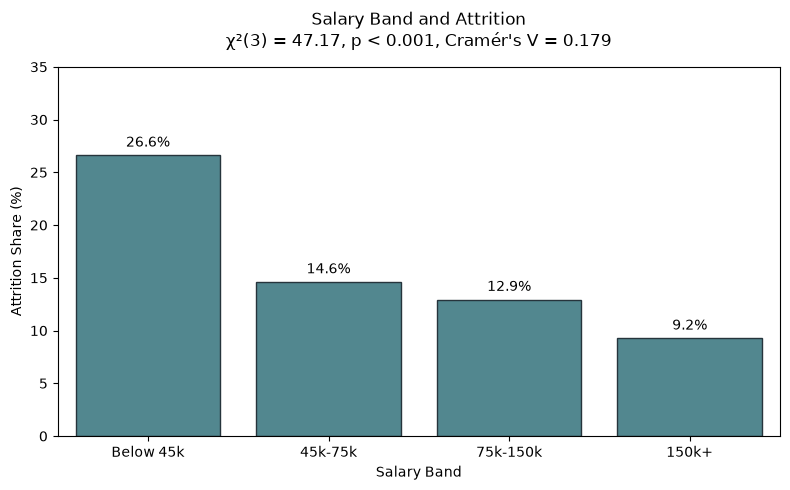

In [32]:
# Attrition share by salary band
salary_share = (
    table_salary["Yes"] / table_salary.sum(axis=1) * 100
).reset_index(name="Attrition Share (%)")

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=salary_share,
    x="SalaryBand",
    y="Attrition Share (%)",
    color="#488E99",
    edgecolor="#26343C",
    linewidth=1.0,
    errorbar=None,
    ax=ax
)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4)

p_text = "p < 0.001" if p_salary < 0.001 else f"p = {p_salary:.3f}"

ax.set_title(
    f"Salary Band and Attrition\n"
    f"χ²({dof_salary}) = {chi2_salary:.2f}, {p_text}, Cramér's V = {cramers_v_salary:.3f}",
    pad=15
)

ax.set_xlabel("Salary Band")
ax.set_ylabel("Attrition Share (%)")
ax.set_ylim(0, 35)

plt.tight_layout()
plt.show()

## Salary vs Attrition: Mann-Whitney Test

In [33]:
from scipy.stats import shapiro

# Salary distribution normality by attrition status
for status in ["No", "Yes"]:
    salary = df_workforce.loc[df_workforce["Attrition"] == status, "Salary"].dropna()

    w, p_value = shapiro(salary)

    print("Attrition:", status)
    print("N:", len(salary))
    print("Skewness:", round(salary.skew(), 3))
    print("Kurtosis:", round(salary.kurt(), 3))
    print("Shapiro-Wilk W:", round(w, 3))
    print("p-value:", "< 0.001" if p_value < 0.001 else round(p_value, 4))
    print()

Attrition: No
N: 1233
Skewness: 1.681
Kurtosis: 2.441
Shapiro-Wilk W: 0.792
p-value: < 0.001

Attrition: Yes
N: 237
Skewness: 2.621
Kurtosis: 8.521
Shapiro-Wilk W: 0.686
p-value: < 0.001



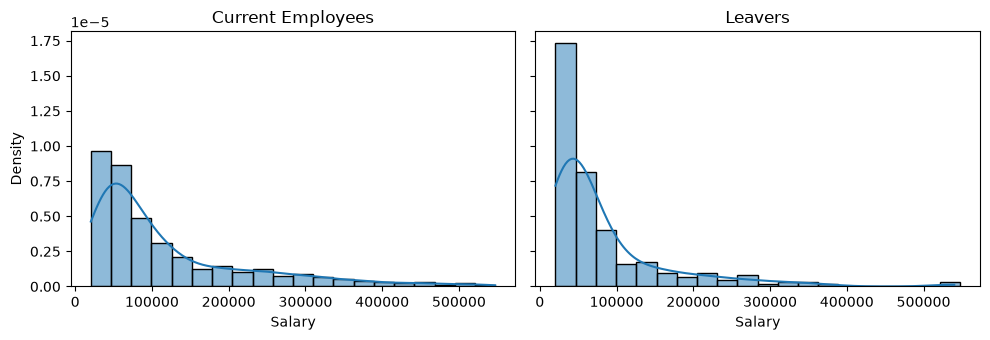

In [34]:
# Salary distribution by attrition status
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True, sharey=True)

bins = np.linspace(df_workforce["Salary"].min(), df_workforce["Salary"].max(), 21)

sns.histplot(
    data=df_workforce[df_workforce["Attrition"] == "No"],
    x="Salary",
    bins=bins,
    kde=True,
    stat="density", # density because groups has different counts
    ax=axes[0]
)

sns.histplot(
    data=df_workforce[df_workforce["Attrition"] == "Yes"],
    x="Salary",
    bins=bins,
    kde=True,
    stat="density",
    ax=axes[1]
)

axes[0].set_title("Current Employees")
axes[1].set_title("Leavers")

axes[0].set_xlabel("Salary")
axes[1].set_xlabel("Salary")

axes[0].set_ylabel("Density")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

# Very small density values resulting in Matplotlib using scientific notation with a scaling factor of 10⁻⁵ (1e−5) - left corner

> High skewness and kurtosis values, along with a statistically significant Shapiro–Wilk test result, indicating substantial deviations from normality in the salary distribution.

In [35]:
from scipy.stats import mannwhitneyu

In [36]:
# Salary by attrition status
salary_current = df_workforce.loc[df_workforce["Attrition"] == "No", "Salary"].dropna()
salary_leavers = df_workforce.loc[df_workforce["Attrition"] == "Yes", "Salary"].dropna()

In [37]:
# Mann-Whitney U test
u, p_mw = mannwhitneyu(
    salary_leavers,
    salary_current,
    alternative="two-sided"
)

print("U statistic:", u)
print("p-value:", "< 0.001" if p_mw < 0.001 else round(p_mw, 4))
print("Leavers:", len(salary_leavers))
print("Current employees:", len(salary_current))

U statistic: 106146.5
p-value: < 0.001
Leavers: 237
Current employees: 1233


In [38]:
# Salary descriptive statistics by attrition status
salary_stats = df_workforce.groupby("Attrition")["Salary"].describe()

salary_stats["IQR"] = salary_stats["75%"] - salary_stats["25%"]

salary_stats = salary_stats[["count", "50%", "IQR", "mean", "std"]].round(2)
salary_stats.columns = ["N", "Mdn", "IQR", "M", "SD"]

salary_stats

,N,Mdn,IQR,M,SD
Attrition,,,,,
No,1233.0,75816.0,105890.0,118856.43,105903.15
Yes,237.0,50660.0,56498.0,82261.90,82464.10


In [39]:
# Rank-biserial correlation
n1 = len(salary_leavers)
n2 = len(salary_current)

r_rb = 2 * u / (n1 * n2) - 1

print("Rank-biserial correlation:", round(r_rb, 3))

Rank-biserial correlation: -0.274


In [40]:
from scipy.stats import bootstrap

# 95% CI for rank-biserial correlation
def rank_biserial(x, y):
    u_boot = mannwhitneyu(x, y).statistic
    return 2 * u_boot / (len(x) * len(y)) - 1

ci_rb = bootstrap(
    (salary_leavers.to_numpy(), salary_current.to_numpy()),
    rank_biserial,
    vectorized=False,
    n_resamples=2000,
    method="percentile",
    random_state=42
).confidence_interval

print("95% CI:", round(ci_rb.low, 3), "-", round(ci_rb.high, 3))

95% CI: -0.352 - -0.195


In [41]:
# Probability of superiority
probability = u / (n1 * n2)

print("Probability of superiority:", round(probability * 100, 1), "%")

Probability of superiority: 36.3 %


> When we randomly select one employee who left and one who is still employed, in approximately 36% of such comparisons, the employee who left will have a higher salary.

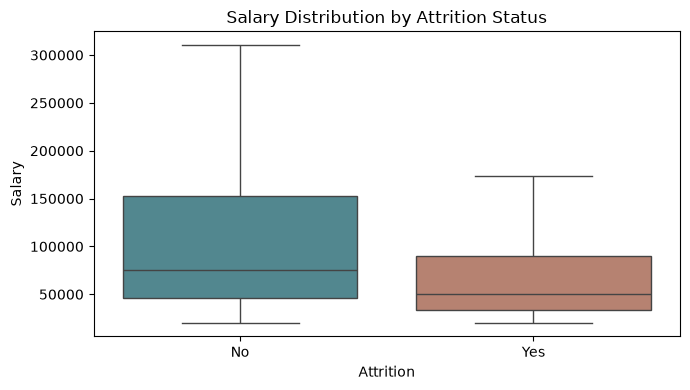

In [42]:
# Salary distribution by attrition status
fig, ax = plt.subplots(figsize=(7, 4))

sns.boxplot(
    data=df_workforce,
    x="Attrition",
    y="Salary",
    order=["No", "Yes"],
    hue="Attrition",
    palette={"No": "#488E99", "Yes": "#C17C66"},
    legend=False,
    showfliers=False,
    linewidth=1.0,
    ax=ax
)

ax.set_title("Salary Distribution by Attrition Status")
ax.set_xlabel("Attrition")
ax.set_ylabel("Salary")

plt.tight_layout()
plt.show()

## StockOptionLevel vs Attrition: Chi-Square Test

In [44]:
#contingency table
table_stock = pd.crosstab(df_workforce["StockOptionLevel"], df_workforce["Attrition"])

table_stock

Attrition,No,Yes
StockOptionLevel,,
0,477,154
1,540,56
2,146,12
3,70,15


In [45]:
# Pearson's Chi-square test
chi2_stock, p_stock, dof_stock, expected_stock = chi2_contingency(
    table_stock,
    correction=False
)

print(f"Chi-square: {chi2_stock:.2f}")
print("p-value:", "< 0.001" if p_stock < 0.001 else round(p_stock, 4))
print(f"Degrees of freedom: {dof_stock}")
print(f"Minimum expected count: {expected_stock.min():.2f}")

Chi-square: 60.60
p-value: < 0.001
Degrees of freedom: 3
Minimum expected count: 13.70


In [46]:
# Cramer's V
n = table_stock.to_numpy().sum()
cramers_v_stock = np.sqrt(chi2_stock / (n * (min(table_stock.shape) - 1)))

print("Cramér's V:", round(cramers_v_stock, 3))

Cramér's V: 0.203


> Statistically significant

> A relatively weak association between the variables

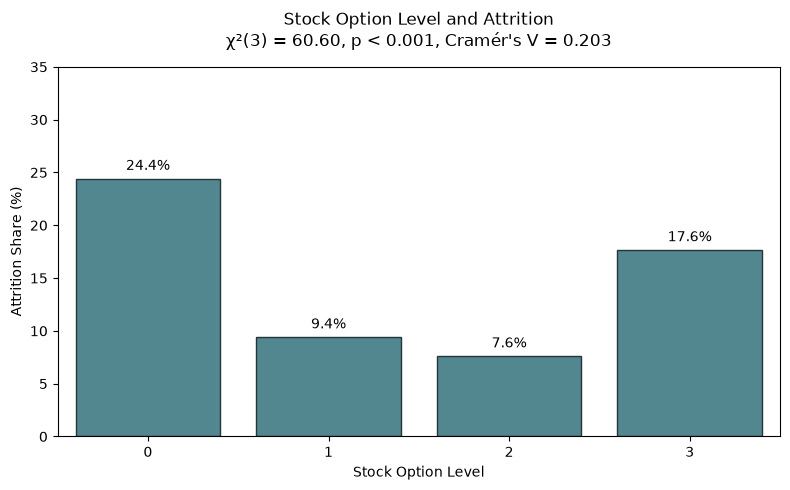

In [49]:
# Attrition share by stock option level
salary_share = (
    table_stock["Yes"] / table_stock.sum(axis=1) * 100
).reset_index(name="Attrition Share (%)")

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=salary_share,
    x="StockOptionLevel",
    y="Attrition Share (%)",
    color="#488E99",
    edgecolor="#26343C",
    linewidth=1.0,
    errorbar=None,
    ax=ax
)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4)

p_text = "p < 0.001" if p_stock < 0.001 else f"p = {p_stock:.3f}"

ax.set_title(
    f"Stock Option Level and Attrition\n"
    f"χ²({dof_stock}) = {chi2_stock:.2f}, {p_text}, Cramér's V = {cramers_v_stock:.3f}",
    pad=15
)

ax.set_xlabel("Stock Option Level")
ax.set_ylabel("Attrition Share (%)")
ax.set_ylim(0, 35)

plt.tight_layout()
plt.show()

### StockOptionLevel 0 vs Other Levels

In [50]:
# Stock Option Level 0 vs Levels 1-3 - contingency table
df_workforce["StockOptionGroup"] = np.where(df_workforce["StockOptionLevel"] == 0,"Level 0","Levels 1-3")

table_stock_2x2 = pd.crosstab(df_workforce["StockOptionGroup"], df_workforce["Attrition"])

table_stock_2x2

Attrition,No,Yes
StockOptionGroup,,
Level 0,477,154
Levels 1-3,756,83


In [51]:
# Odds Ratio and 95% Confidence Interval
stock_result = Table2x2(table_stock_2x2.loc[["Level 0", "Levels 1-3"], ["Yes", "No"]].to_numpy())
ci_low_stock, ci_high_stock = stock_result.oddsratio_confint()

print("Odds Ratio:", round(stock_result.oddsratio, 2))
print("95% CI:", round(ci_low_stock, 2), "-", round(ci_high_stock, 2))

Odds Ratio: 2.94
95% CI: 2.2 - 3.93


> Employees with a Stock Option Level of 0 are approximately 2.94 times more likely to attrition than employees with levels 1–3.
> The confidence interval does not include the value 1, which indicates a statistically significant relationship.

In [52]:
# Risk Difference
share_stock0 = table_stock_2x2.loc["Level 0", "Yes"] / table_stock_2x2.loc["Level 0"].sum()
share_stock_other = table_stock_2x2.loc["Levels 1-3", "Yes"] / table_stock_2x2.loc["Levels 1-3"].sum()

risk_diff_stock = (share_stock0 - share_stock_other) * 100

print("Level 0:", round(share_stock0 * 100, 2), "%")
print("Levels 1-3:", round(share_stock_other * 100, 2), "%")
print("Risk Difference:", round(risk_diff_stock, 2), "pp")

Level 0: 24.41 %
Levels 1-3: 9.89 %
Risk Difference: 14.51 pp


In [53]:
# 95% CI for Risk Difference
ci_rd_low_stock, ci_rd_high_stock = confint_proportions_2indep(
    table_stock_2x2.loc["Level 0", "Yes"],
    table_stock_2x2.loc["Level 0"].sum(),
    table_stock_2x2.loc["Levels 1-3", "Yes"],
    table_stock_2x2.loc["Levels 1-3"].sum(),
    method="newcomb"
)

print("Risk Difference:", round(risk_diff_stock, 2), "pp")
print("95% CI:", round(ci_rd_low_stock * 100, 2), "-",
      round(ci_rd_high_stock * 100, 2), "pp")

Risk Difference: 14.51 pp
95% CI: 10.63 - 18.47 pp


## Department × OverTime vs Attrition: logistic regression

In [54]:
# Overtime vs Attrition by Department table
table_dept_ot = pd.crosstab([df_workforce["Department"], df_workforce["OverTime"]], df_workforce["Attrition"])

table_dept_ot

Attrition                  No  Yes
Department      OverTime          
Human Resources No         39    7
                Yes        12    5
Sales           No        274   44
                Yes        80   48
Technology      No        631   59
                Yes       197   74

In [56]:
# Odds Ratio by Department
hr = Table2x2(table_dept_ot.loc["Human Resources"].loc[["Yes", "No"], ["Yes", "No"]].to_numpy())
sales = Table2x2(table_dept_ot.loc["Sales"].loc[["Yes", "No"], ["Yes", "No"]].to_numpy())
tech = Table2x2(table_dept_ot.loc["Technology"].loc[["Yes", "No"], ["Yes", "No"]].to_numpy())

# 95% Confidence Intervals
hr_ci = hr.oddsratio_confint()
sales_ci = sales.oddsratio_confint()
tech_ci = tech.oddsratio_confint()

# Results table
dept_results = pd.DataFrame({
    "Department": ["Human Resources", "Sales", "Technology"],
    "OR": [hr.oddsratio, sales.oddsratio, tech.oddsratio],
    "CI Low": [hr_ci[0], sales_ci[0], tech_ci[0]],
    "CI High": [hr_ci[1], sales_ci[1], tech_ci[1]]
})

dept_results["N"] = dept_results["Department"].map(df_workforce["Department"].value_counts())

dept_results.round(2)

,Department,OR,CI Low,CI High,N
0,Human Resources,2.32,0.62,8.67,63
1,Sales,3.74,2.31,6.03,446
2,Technology,4.02,2.75,5.86,961


In [68]:
import statsmodels.formula.api as smf

# Logistic regression without interaction
model_base = smf.logit("AttritionBinary ~ C(Department) + C(OverTime)", data=df_workforce).fit(disp=False)

# Logistic regression with interaction
model_interaction = smf.logit("AttritionBinary ~ C(Department) * C(OverTime)", data=df_workforce).fit(disp=False)

# Overall model significance
print("Base model LR chi-square:", round(model_base.llr, 3))
print("Base model p-value:", "< 0.001" if model_base.llr_pvalue < 0.001 else round(model_base.llr_pvalue, 4))

print("\nInteraction model LR chi-square:", round(model_interaction.llr, 3))
print("Interaction model p-value:", "< 0.001" if model_interaction.llr_pvalue < 0.001 else round(model_interaction.llr_pvalue, 4))

Base model LR chi-square: 92.351
Base model p-value: < 0.001

Interaction model LR chi-square: 92.98
Interaction model p-value: < 0.001


In [69]:
# Base model coefficients
model_base.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:        AttritionBinary   No. Observations:                 1470
Model:                          Logit   Df Residuals:                     1466
Method:                           MLE   Df Model:                            3
Date:                Tue, 27 Oct 2026   Pseudo R-squ.:                 0.07112
Time:                        10:28:10   Log-Likelihood:                -603.12
converged:                       True   LL-Null:                       -649.29
Covariance Type:            nonrobust   LLR p-value:                 6.847e-20
===============================================================================================
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -1.9172      0.338     -5.665      0.000      -2.580      -1.254
C(Department)[T.Sales]          0.0796      0.354      0.225      0.822      -0.614       0.773
C(Department)[T.Technology]    -0.4264      0.346     -1.232      0.218      -1.105       0.252
C(OverTime)[T.Yes]              1.3376      0.147      9.073      0.000       1.049       1.627
===============================================================================================
"""

In [71]:
base_results = pd.DataFrame({
    "OR": np.exp(model_base.params),
    "CI Low": np.exp(model_base.conf_int()[0]),
    "CI High": np.exp(model_base.conf_int()[1]),
    "p-value": model_base.pvalues
})

base_results.round(3)

,OR,CI Low,CI High,p-value
Intercept,0.147,0.076,0.285,0.000
C(Department)[T.Sales],1.083,0.541,2.167,0.822
C(Department)[T.Technology],0.653,0.331,1.287,0.218
C(OverTime)[T.Yes],3.810,2.854,5.087,0.000


In [70]:
model_interaction.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:        AttritionBinary   No. Observations:                 1470
Model:                          Logit   Df Residuals:                     1464
Method:                           MLE   Df Model:                            5
Date:                Tue, 27 Oct 2026   Pseudo R-squ.:                 0.07160
Time:                        10:28:47   Log-Likelihood:                -602.80
converged:                       True   LL-Null:                       -649.29
Covariance Type:            nonrobust   LLR p-value:                 1.589e-18
==================================================================================================================
                                                     coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------
Intercept                                         -1.7177      0.410     -4.184      0.000      -2.522      -0.913
C(Department)[T.Sales]                            -0.1113      0.441     -0.252      0.801      -0.977       0.754
C(Department)[T.Technology]                       -0.6521      0.432     -1.508      0.132      -1.500       0.196
C(OverTime)[T.Yes]                                 0.8422      0.672      1.253      0.210      -0.475       2.160
C(Department)[T.Sales]:C(OverTime)[T.Yes]          0.4759      0.715      0.665      0.506      -0.926       1.878
C(Department)[T.Technology]:C(OverTime)[T.Yes]     0.5484      0.699      0.784      0.433      -0.822       1.919
==================================================================================================================
"""

In [73]:
interaction_results = pd.DataFrame({
    "OR": np.exp(model_interaction.params),
    "CI Low": np.exp(model_interaction.conf_int()[0]),
    "CI High": np.exp(model_interaction.conf_int()[1]),
    "p-value": model_interaction.pvalues
})

interaction_results.round(3)

,OR,CI Low,CI High,p-value
Intercept,0.179,0.080,0.401,0.000
C(Department)[T.Sales],0.895,0.377,2.125,0.801
C(Department)[T.Technology],0.521,0.223,1.216,0.132
C(OverTime)[T.Yes],2.321,0.622,8.668,0.210
C(Department)[T.Sales]:C(OverTime)[T.Yes],1.610,0.396,6.539,0.506
C(Department)[T.Technology]:C(OverTime)[T.Yes],1.731,0.440,6.814,0.433


Model 1 (base): Is there a link between overtime and employee departures, when broken down by department?
> Overtime remains significantly associated with attrition after adjusting for Department (OR = 3.81, p < 0.001). <br>
> Sales and Technology do not differ significantly from the HR reference group.

Model 2 (interactions): Does the relationship between overtime and departures vary across departments?
> Neither interaction coefficient is statistically significant <br>
> No evidence that the overtime-attrition association differs across departments.

**Likelihood Ratio Test:**

> H₀: The relationship between OverTime and Attrition is the same across all departments, on the OR (odds ratio) scale. <br>
> H₁: The relationship differs between at least two departments.

In [60]:
from scipy.stats import chi2 as chi2_dist

# Likelihood Ratio Test
lr_stat = 2 * (model_interaction.llf - model_base.llf)

df_diff = int(model_interaction.df_model - model_base.df_model)

p_interaction = chi2_dist.sf(lr_stat, df_diff)

print("Likelihood Ratio Chi-square:", round(lr_stat, 3))
print("Degrees of freedom:", df_diff)
print("p-value:", round(p_interaction, 4))

Likelihood Ratio Chi-square: 0.629
Degrees of freedom: 2
p-value: 0.7303


> no significant differences between departments; Adding the Department × OverTime interaction does not significantly improve the model fit. <br>
> The simpler model without interaction is preferred.

In [62]:
# Attrition share by department and overtime
dept_share = (
    df_workforce.groupby(["Department", "OverTime"])["AttritionBinary"]
    .mean()
    .mul(100)
    .reset_index(name="Attrition Share (%)")
)

dept_share

,Department,OverTime,Attrition Share (%)
0,Human Resources,No,15.217391
1,Human Resources,Yes,29.411765
2,Sales,No,13.836478
3,Sales,Yes,37.500000
4,Technology,No,8.550725
5,Technology,Yes,27.306273


In [63]:
# Difference between overtime groups
dept_diff = dept_share.pivot(
    index="Department",
    columns="OverTime",
    values="Attrition Share (%)"
)

dept_diff["Difference (pp)"] = dept_diff["Yes"] - dept_diff["No"]

dept_diff.round(2)

OverTime,No,Yes,Difference (pp)
Department,,,
Human Resources,15.22,29.41,14.19
Sales,13.84,37.50,23.66
Technology,8.55,27.31,18.76


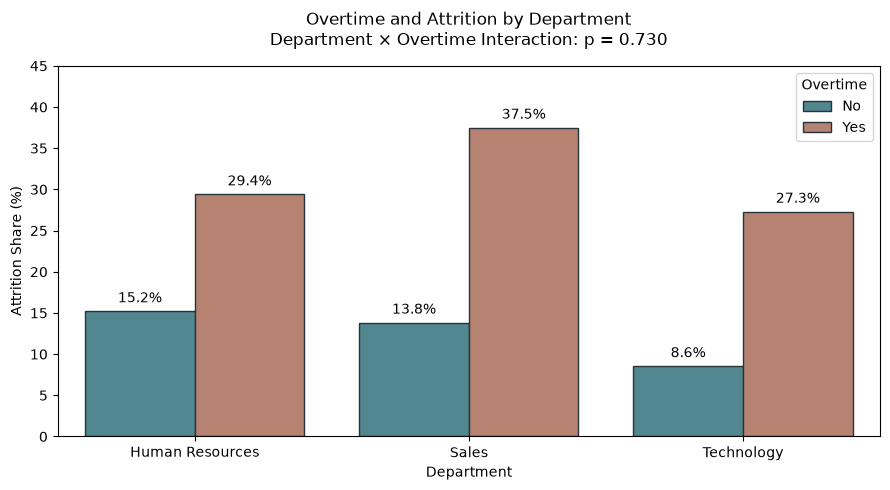

In [74]:
# Overtime and attrition by department
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=dept_share,
    x="Department",
    y="Attrition Share (%)",
    hue="OverTime",
    order=["Human Resources", "Sales", "Technology"],
    hue_order=["No", "Yes"],
    palette={"No": "#488E99", "Yes": "#C17C66"},
    edgecolor="#26343C",
    linewidth=1.0,
    errorbar=None,
    ax=ax
)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4)
ax.bar_label(ax.containers[1], fmt="%.1f%%", padding=4)

ax.set_title(
    f"Overtime and Attrition by Department\n"
    f"Department × Overtime Interaction: p = {p_interaction:.3f}",
    pad=15
)

ax.set_xlabel("Department")
ax.set_ylabel("Attrition Share (%)")
ax.set_ylim(0, 45)
ax.legend(title="Overtime")

plt.tight_layout()
plt.show()